In [ ]:
import pandas as pd 
# 1. Load the dataset  
df = pd.read_csv(r"C:\Users\maild\OneDrive\Desktop\UTDMSBA\2026.Fall\BUAN6341.AppliedML\GROUP.Project\Work\college_majors_2026.csv") 

# 2 Inspect overall dataset dimensions 
print(f"Total Rows (Programs): {df.shape[0]:,}") 
print(f"Total Columns (Features): {df.shape[1]}")

Total Rows (Programs): 227,980
Total Columns (Features): 72


In [5]:
# Display column names, non-null counts, and data types 
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 227980 entries, 0 to 227979
Data columns (total 72 columns):
 #   Column                                Non-Null Count   Dtype  
---  ------                                --------------   -----  
 0   program_id                            227980 non-null  str    
 1   unitid                                220960 non-null  float64
 2   opeid6                                227980 non-null  int64  
 3   institution_name                      227980 non-null  str    
 4   institution_control                   227980 non-null  str    
 5   is_main_campus                        227980 non-null  int64  
 6   institution_city                      216684 non-null  str    
 7   institution_state                     216684 non-null  str    
 8   institution_region                    216684 non-null  str    
 9   institution_latitude                  216684 non-null  float64
 10  institution_longitude                 216684 non-null  float64
 11  institution

In [12]:
#Let us first examine the Program Breakdown in the raw data. 

import pandas as pd 
# 1. Load raw dataset 
df = pd.read_csv(r"C:\Users\maild\OneDrive\Desktop\UTDMSBA\2026.Fall\BUAN6341.AppliedML\GROUP.Project\Work\college_majors_2026.csv") 


# 2.Identify the credential column automatically 
cred_cols = [c for c in df.columns if 'credential' in c.lower() or 'level' in c.lower()] 
cred_col = cred_cols[0] if cred_cols else 'credential_level' 
print(f"Credential Column Used: {cred_col}") 
print("========================================") 

# 3. Calculate total counts and percentages across all credential levels 
counts = df[cred_col].value_counts(dropna=False)
percentages = df[cred_col].value_counts(dropna=False, normalize=True) * 100 
credential_summary = pd.DataFrame({ 'Program_Count': counts, 'Percentage': percentages.round(2) })

print("BREAKDOWN OF ALL CREDENTIAL LEVELS IN DATASET:") 
print(credential_summary) 
print("========================================") 

# 4. Check target earnings reporting availability across credential levels 
if 'median_earnings_4yr_usd' in df.columns: 
    reported_earnings = df.groupby(cred_col)['median_earnings_4yr_usd'].count() 
    print("\nREPORTED 4-YEAR EARNINGS BY CREDENTIAL LEVEL:") 
    print(reported_earnings)

Credential Column Used: credential_level
BREAKDOWN OF ALL CREDENTIAL LEVELS IN DATASET:
                  Program_Count  Percentage
credential_level                           
3                         71664       31.43
1                         43465       19.07
2                         42373       18.59
5                         38621       16.94
8                         13921        6.11
6                         12637        5.54
7                          2350        1.03
99                         1700        0.75
4                          1249        0.55

REPORTED 4-YEAR EARNINGS BY CREDENTIAL LEVEL:
credential_level
1      8163
2      9280
3     27617
4       118
5     10403
6      1150
7       737
8       448
99      196
Name: median_earnings_4yr_usd, dtype: int64


In [14]:
import pandas as pd 
#Filter strictly for Bachelor's Degrees (level 3) with reported 4-year earnings bachelors 
bachelors_df = df[(df['credential_level'] == 3) & (df['median_earnings_4yr_usd'].notnull())].copy() 
print("========================================") 
print(f"Filtered Bachelor's Subset Shape: {bachelors_df.shape}") 
print("========================================")

Filtered Bachelor's Subset Shape: (27617, 72)


In [15]:
import pandas as pd


# 1. Calculate missing values per column
missing_counts = bachelors_df.isnull().sum()
missing_pct = (missing_counts / len(bachelors_df)) * 100

# 2. Combine into a summary DataFrame (only showing columns with missing values)
missing_summary = pd.DataFrame({
    'Missing_Count': missing_counts,
    'Missing_Percentage': missing_pct.round(2)
})

# Filter to show only columns that actually have missing values
missing_summary = missing_summary[missing_summary['Missing_Count'] > 0].sort_values(by='Missing_Count', ascending=False)

print("========================================")
print(f"COLUMNS WITH MISSING VALUES ({len(missing_summary)} out of 72 columns):")
print("========================================")
print(missing_summary.to_string())

COLUMNS WITH MISSING VALUES (47 out of 72 columns):
                                      Missing_Count  Missing_Percentage
ai_tool_examples                              16621               60.18
count_working_in_state_5yr                    10374               37.56
pct_working_in_state_5yr                      10374               37.56
institution_avg_sat                            8623               31.22
earnings_growth_pct_1yr_to_5yr                 7724               27.97
earnings_trajectory_category                   7724               27.97
pct_above_hs_threshold_5yr                     7263               26.30
count_above_hs_threshold_5yr                   7263               26.30
median_earnings_5yr_usd                        5663               20.51
earnings_cohort_size_5yr                       5663               20.51
pct_working_5yr                                5663               20.51
debt_to_earnings_1yr                           5132               18.58
payment_to_i

In [16]:
# 1. Define features to drop (leakage features, ultra-high missingness text, and duplicate IDs)
cols_to_drop = [
    'ai_tool_examples',             # 60%+ missing text
    'median_earnings_5yr_usd',      # Target leakage (future data)
    'earnings_growth_pct_1yr_to_5yr', # Target leakage
    'count_working_in_state_5yr',   # High missingness
    'pct_working_in_state_5yr'      # High missingness
]

# 2. Apply column drops
cleaned_bachelors_df = bachelors_df.drop(columns=[c for c in cols_to_drop if c in bachelors_df.columns])

print("========================================")
print(f"Original Bachelor's Shape: {bachelors_df.shape}")
print(f"Cleaned Bachelor's Shape: {cleaned_bachelors_df.shape}")
print("========================================")

Original Bachelor's Shape: (27617, 72)
Cleaned Bachelor's Shape: (27617, 67)


In [ ]:
#Before we split the data or train models, we need to inspect our continuous target variable (**median_earnings_4yr_usd*). 
#In economic and salary datasets, earnings are almost always right-skewed (a long tail of very high earners), which can heavily bias linear regression models if not addressed.

# Target variable summary statistics & skewness 
target = cleaned_bachelors_df['median_earnings_4yr_usd'] 
print("========================================") 
print("TARGET VARIABLE SUMMARY STATISTICS (median_earnings_4yr_usd):") 
print("========================================") 
print(target.describe().round(2)) 
print("----------------------------------------") 
print(f"Skewness Score: {target.skew():.2f}") 
print("========================================")

TARGET VARIABLE SUMMARY STATISTICS (median_earnings_4yr_usd):
count     27617.00
mean      64251.85
std       20786.33
min       16087.00
25%       49818.00
50%       59399.00
75%       75345.00
max      297029.00
Name: median_earnings_4yr_usd, dtype: float64
----------------------------------------
Skewness Score: 1.44


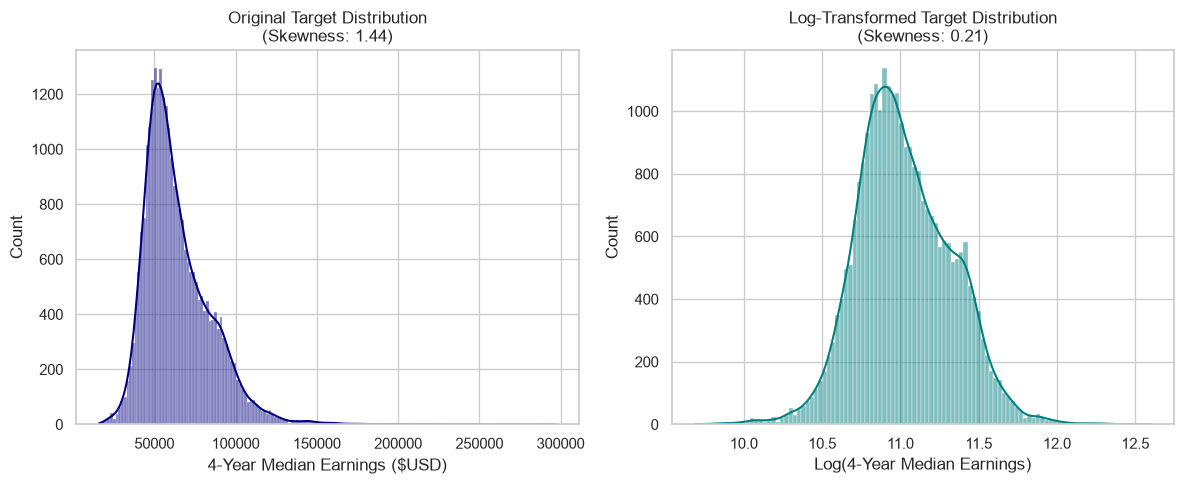

In [ ]:
#To confirm the skewness reduction visually for our report, we generate a side-by-side histogram comparing the raw target distribution against the log-transformed distribution. 
#Log transformation is a common technique to reduce skewness in continuous variables, especially for financial data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set clean visual style
sns.set_theme(style="whitegrid")

# Create side-by-side target distribution comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot Raw Target
sns.histplot(bachelors_df['median_earnings_4yr_usd'], kde=True, ax=axes[0], color='navy')
axes[0].set_title(f"Original Target Distribution\n(Skewness: {bachelors_df['median_earnings_4yr_usd'].skew():.2f})")
axes[0].set_xlabel("4-Year Median Earnings ($USD)")

# Plot Log-Transformed Target
log_earnings = np.log1p(bachelors_df['median_earnings_4yr_usd'])
sns.histplot(log_earnings, kde=True, ax=axes[1], color='teal')
axes[1].set_title(f"Log-Transformed Target Distribution\n(Skewness: {log_earnings.skew():.2f})")
axes[1].set_xlabel("Log(4-Year Median Earnings)")

plt.tight_layout()
plt.savefig("plot1_target_distribution.png", dpi=300)
plt.show()

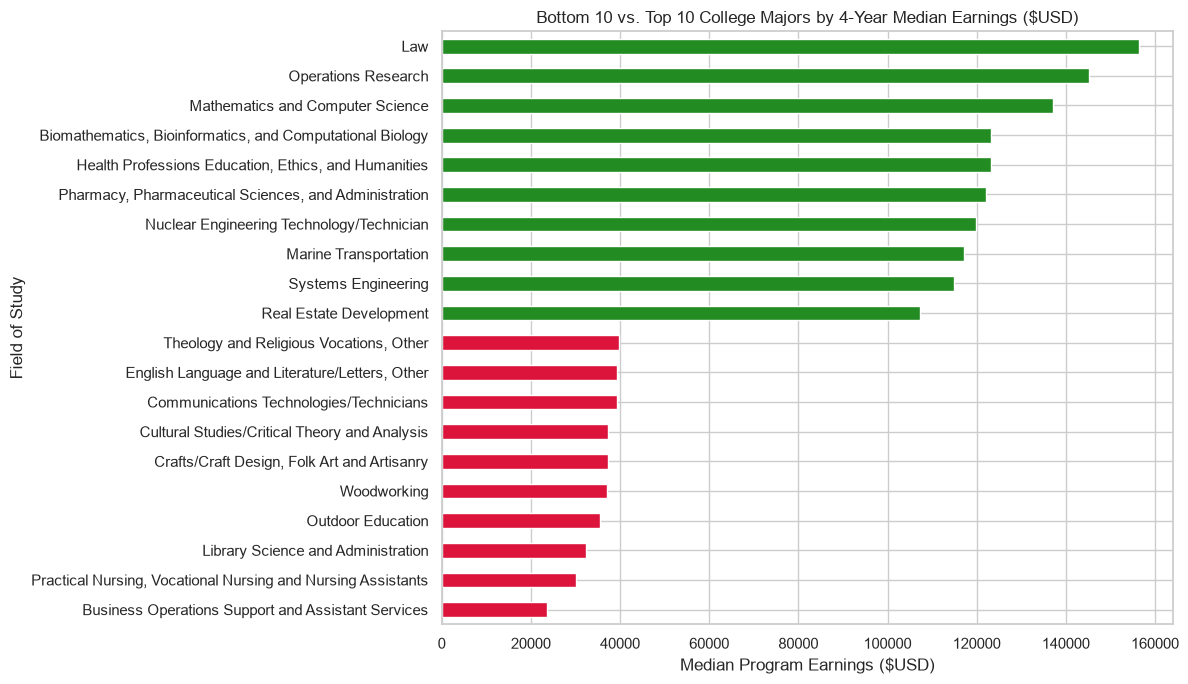

In [ ]:
# One of our main points in the Motivation section was that financial outcomes vary drastically depending on the field of study.
# This visualization aggregates program medians by field of study (`cip_title`) 
# It displays a horizontal bar chart comparing the **10 lowest-earning majors** (red) against the **10 highest-earning majors** (green).


# Identify major field column name
major_col = 'cip_title' if 'cip_title' in bachelors_df.columns else 'field_of_study'

# Calculate median 4-year earnings per major field
major_summary = bachelors_df.groupby(major_col)['median_earnings_4yr_usd'].median().sort_values()

# Select Bottom 10 and Top 10 majors
top_bottom = pd.concat([major_summary.head(10), major_summary.tail(10)])
colors = ['crimson']*10 + ['forestgreen']*10

# Plot horizontal bar chart
plt.figure(figsize=(12, 7))
top_bottom.plot(kind='barh', color=colors)
plt.title("Bottom 10 vs. Top 10 College Majors by 4-Year Median Earnings ($USD)")
plt.xlabel("Median Program Earnings ($USD)")
plt.ylabel("Field of Study")
plt.tight_layout()
plt.savefig("plot2_top_bottom_majors.png", dpi=300)
plt.show()


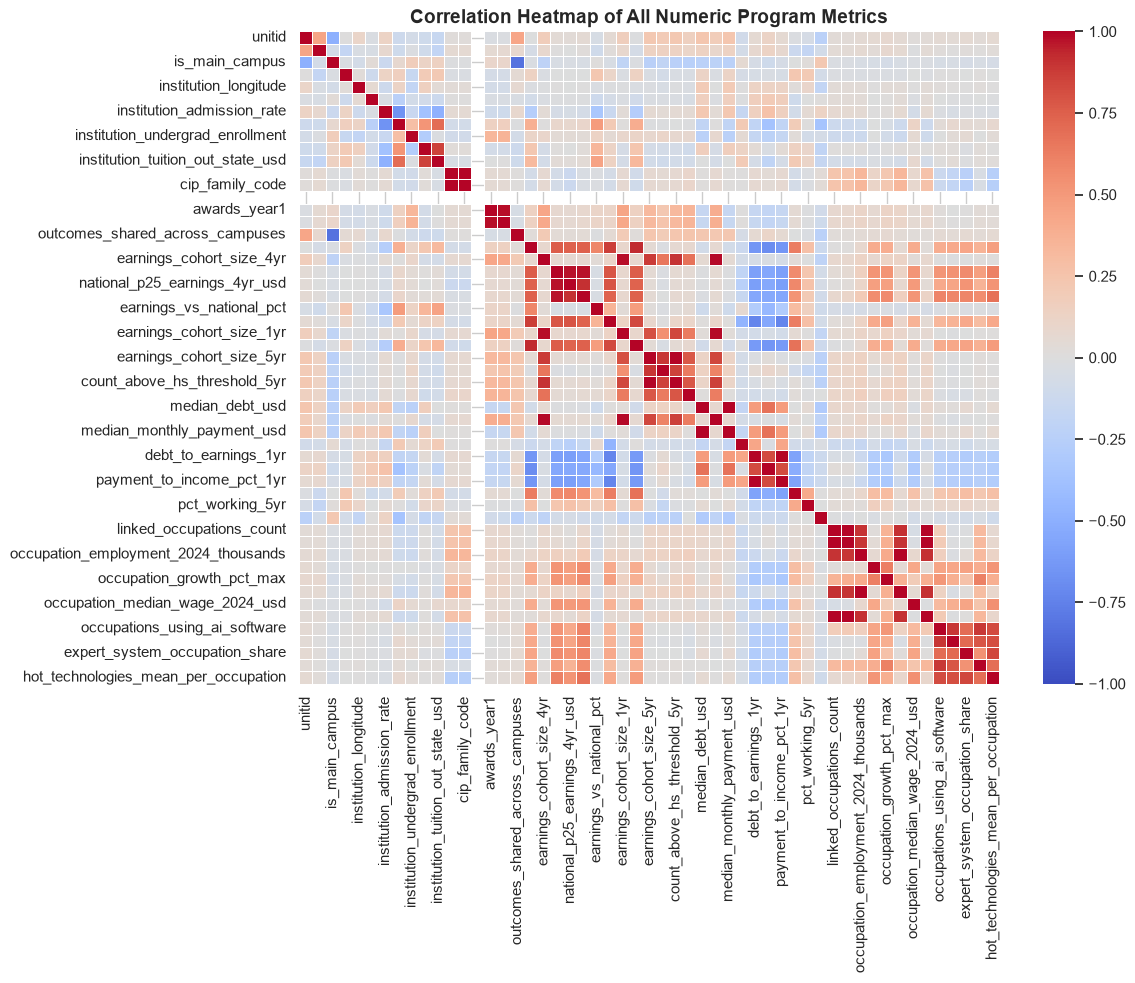

In [ ]:
# Correlation Heatmap of Key Predictors

# Now let's examine how our key numerical predictors correlate with one another and with our target variable (`median_earnings_4yr_usd`).
# This heatmap checks for:
# Feature Relationships: How strongly metrics like Ai scores, projected job growth, in-state tuition, and student debt correlate with 4-year earnings.
# Multicollinearity: Identifying highly correlated predictor pairs (e.g., tuition vs. debt) before training linear models.

#import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Ensure your bachelors_df is loaded and filtered
# df = pd.read_csv("college_majors_2026.csv")
# bachelors_df = df[(df['credential_level'] == 3) & (df['median_earnings_4yr_usd'].notnull())].copy()

# 2. Automatically grab ALL numeric columns in the dataframe
numeric_cols = bachelors_df.select_dtypes(include=[np.number]).columns.tolist()

# 3. Ensure 'median_earnings_4yr_usd' is explicitly included if it somehow got left out
if 'median_earnings_4yr_usd' not in numeric_cols:
    numeric_cols.append('median_earnings_4yr_usd')

print(f"Total numeric columns found: {len(numeric_cols)}")

# 4. Compute correlation matrix across all numeric columns
corr_matrix = bachelors_df[numeric_cols].corr()

# 5. Generate a large, readable heatmap
plt.figure(figsize=(16, 14))
sns.heatmap(
    corr_matrix, 
    annot=False,          # Turn off annotations (too crowded for 27+ variables)
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.2
)
plt.title("Full Correlation Heatmap of All Numeric Program Metrics", fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("plot3_full_correlation_heatmap.png", dpi=300)
plt.show()

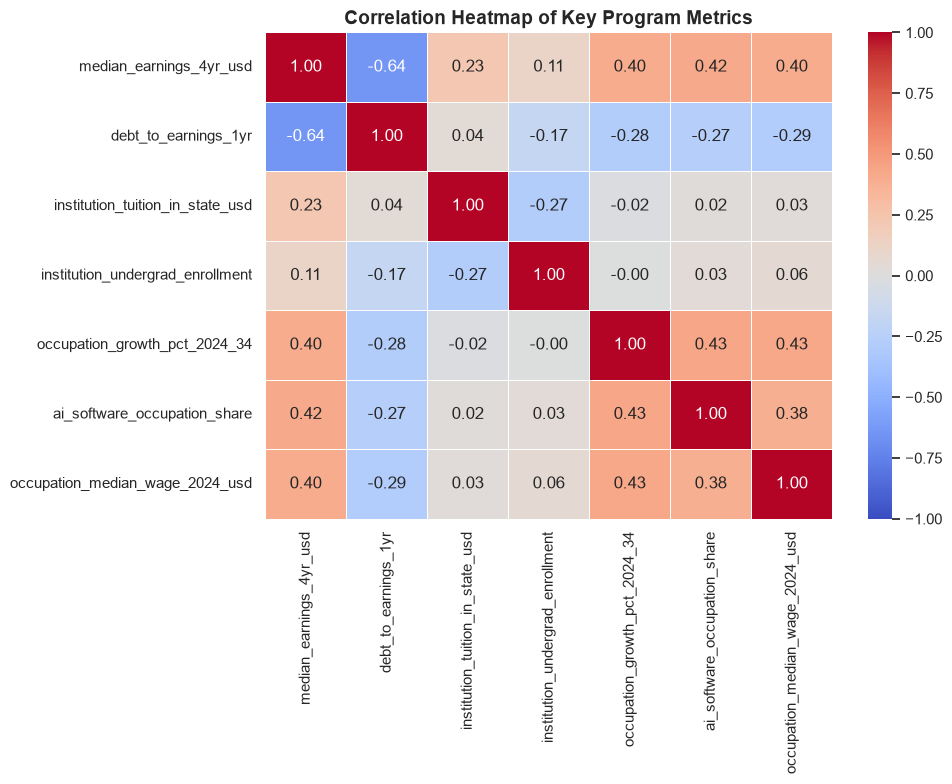

In [3]:
# Another way of pulling up the some specific numerical columns for the heatmap

# Select numeric columns present in your raw dataset
numeric_cols = [
    'median_earnings_4yr_usd',
    'debt_to_earnings_1yr',
    'institution_tuition_in_state_usd',
    'institution_undergrad_enrollment',
    'occupation_growth_pct_2024_34',
    'ai_software_occupation_share',
    'occupation_median_wage_2024_usd'
]

# Filter to keep columns that exist
valid_cols = [c for c in numeric_cols if c in bachelors_df.columns]

# Compute correlation matrix
corr_matrix = bachelors_df[valid_cols].corr()

# Generate heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5)
plt.title("Correlation Heatmap of Key Program Metrics", fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig("plot3_correlation_heatmap.png", dpi=300)
plt.show()

Filtered down to 50 meaningful numeric variables for correlation.


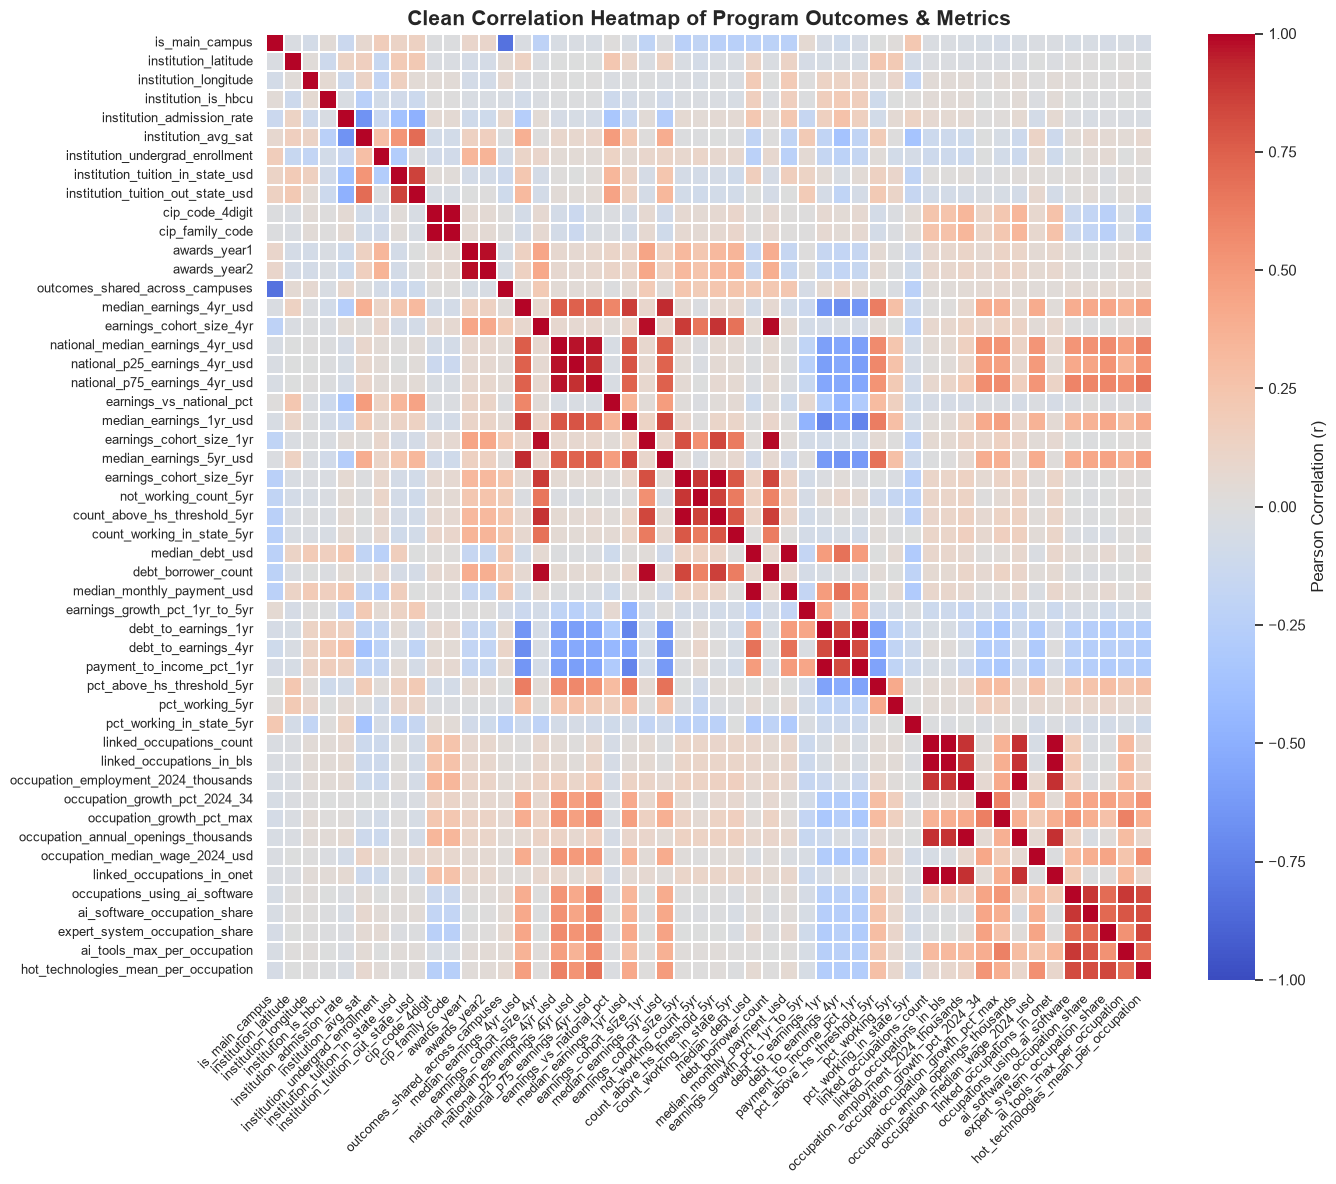

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# 1. Load and filter our Bachelor's subset
df = pd.read_csv("college_majors_2026.csv")
bachelors_df = df[(df['credential_level'] == 3) & (df['median_earnings_4yr_usd'].notnull())].copy()

# 2. Automatically grab numeric columns, but EXCLUDE ID / administrative columns
# that are technically numbers but have no correlation meaning (e.g., unitid, opeid, zip codes, etc.)
exclude_cols = ['unitid', 'opeid', 'opeid6', 'credential_level', 'cip_code']

# Select numeric columns excluding the identifiers above
numeric_cols = [
    col for col in bachelors_df.select_dtypes(include=[np.number]).columns 
    if col not in exclude_cols
]

# Ensure our key target is explicitly included
if 'median_earnings_4yr_usd' not in numeric_cols:
    numeric_cols.append('median_earnings_4yr_usd')

print(f"Filtered down to {len(numeric_cols)} meaningful numeric variables for correlation.")

# 3. Compute the correlation matrix
corr_matrix = bachelors_df[numeric_cols].corr()

# 4. Generate a properly scaled, readable heatmap
plt.figure(figsize=(14, 12))
sns.heatmap(
    corr_matrix, 
    annot=False,          # Keep False if >15 variables to avoid overcrowding
    cmap="coolwarm", 
    vmin=-1, 
    vmax=1, 
    linewidths=0.3,
    cbar_kws={'label': 'Pearson Correlation (r)'}
)
plt.title("Clean Correlation Heatmap of Program Outcomes & Metrics", fontsize=15, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.yticks(fontsize=9)
plt.tight_layout()
plt.savefig("plot3_clean_correlation_heatmap.png", dpi=300)
plt.show()

In [4]:
# Cleaned Dataset for Modeling
# Run this code to generate a master cleaned CSV for modeling and analysis.

import pandas as pd
import numpy as np

# 1. Load Raw Dataset
df = pd.read_csv("college_majors_2026.csv")

# 2. Replace common text string placeholders with true np.nan
df = df.replace(['PrivacySuppressed', 'None', 'null', 'NaN', ''], np.nan)

# 3. Filter strictly for U.S. Bachelor's degrees (Level 3) with reported earnings
bachelors_df = df[(df['credential_level'] == 3) & (df['median_earnings_4yr_usd'].notnull())].copy()

# Ensure numeric casting
bachelors_df['median_earnings_4yr_usd'] = pd.to_numeric(bachelors_df['median_earnings_4yr_usd'], errors='coerce')
bachelors_df['institution_undergrad_enrollment'] = pd.to_numeric(bachelors_df['institution_undergrad_enrollment'], errors='coerce')


#`payment_to_income_pct_1yr` measures the 1st-year loan payment as a percentage of 1st-year earnings
# Without coercing: If `payment_to_income_pct_1yr` is still stored as text (`object`), running > 8.0 will crash Python with a error: `TypeError: > not supported between instances of 'str' and 'float'`.
# With coercing: Valid string numbers like `"12.4"` become the float `12.4`, while `"PrivacySuppressed"` becomes `NaN`. Now the `> 8.0` check runs smoothly across all rows.

if 'payment_to_income_pct_1yr' in bachelors_df.columns:
    bachelors_df['payment_to_income_pct_1yr'] = pd.to_numeric(bachelors_df['payment_to_income_pct_1yr'], errors='coerce')

# 4. Smart Deduplication on Branch Campuses (opeid6 + cip_code)
if 'opeid6' in bachelors_df.columns and 'cip_code' in bachelors_df.columns:
    bachelors_df = bachelors_df.sort_values(
        by=['institution_undergrad_enrollment', 'debt_borrower_count'], 
        ascending=[False, False]
    )
    bachelors_df = bachelors_df.drop_duplicates(subset=['opeid6', 'cip_code'], keep='first')

# 5. Drop Target Leakage & High-Missingness Text Columns
cols_to_drop = [
    'ai_tool_examples', 
    'median_earnings_5yr_usd', 
    'earnings_growth_pct_1yr_to_5yr', 
    'count_working_in_state_5yr', 
    'pct_working_in_state_5yr'
]
cleaned_df = bachelors_df.drop(columns=[c for c in cols_to_drop if c in bachelors_df.columns])

# 6. Add Continuous Targets (Raw USD & Log Transformed)
cleaned_df['log_median_earnings_4yr_usd'] = np.log1p(cleaned_df['median_earnings_4yr_usd'])

# 7. Add Target 1: High-ROI Classification (1 if >= Median$, else 0)
median_threshold = cleaned_df['median_earnings_4yr_usd'].median()
cleaned_df['is_high_roi'] = (cleaned_df['median_earnings_4yr_usd'] >= median_threshold).astype(int)

# 8. Add Target 2: High Debt-Risk Classification (1 if Payment/Income > 8.0%, else 0)
if 'payment_to_income_pct_1yr' in cleaned_df.columns:
    cleaned_df['is_high_debt_risk'] = (cleaned_df['payment_to_income_pct_1yr'] > 8.0).astype(int)

# 9. Export Master Cleaned CSV
output_filename = "college_majors_bachelors_cleaned.csv"
cleaned_df.to_csv(output_filename, index=False)

print("========================================")
print("MASTER CLEANED CSV SUCCESSFULLY GENERATED!")
print("========================================")
print(f"Final Cleaned Dataset Shape: {cleaned_df.shape}")
print(f"High-ROI Rate: {cleaned_df['is_high_roi'].mean():.2%}")
if 'is_high_debt_risk' in cleaned_df.columns:
    print(f"High Debt-Risk Rate: {cleaned_df['is_high_debt_risk'].mean():.2%}")
print(f"Unique Institutions (opeid6): {cleaned_df['opeid6'].nunique()}")
print("========================================")

MASTER CLEANED CSV SUCCESSFULLY GENERATED!
Final Cleaned Dataset Shape: (27617, 70)
High-ROI Rate: 50.00%
High Debt-Risk Rate: 30.26%
Unique Institutions (opeid6): 1802
